# Big Mart Sales Prediction
### Machine Learning Regression | Internship Project

**Objective:** Predict `Item_Outlet_Sales` from product and outlet characteristics using supervised regression. This notebook is designed for Google Colab. It produces exploratory charts, compares models using a held-out validation set, and exports a submission-style prediction CSV.

> Run all cells in order. Upload `Train.csv` and `Test.csv` when prompted. Metrics and figures in this notebook are computed from your data; they are not pre-invented.

In [1]:
import warnings, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [3]:
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor

print('Upload Train.csv and Test.csv')
uploaded = files.upload()
train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
print('Train shape:', train.shape, '| Test shape:', test.shape)
display(train.head())

Upload Train.csv and Test.csv


Saving Test.csv to Test.csv
Train shape: (8523, 12) | Test shape: (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. Data inspection

In [4]:
print('Train info:'); train.info()
print('\nMissing values (training):'); display(train.isnull().sum().sort_values(ascending=False))
print('\nDuplicates:', train.duplicated().sum())
display(train.describe(include='all').T)

Train info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB

Missing values (training):


,0
Outlet_Size,2410
Item_Weight,1463
Item_Fat_Content,0
Item_Identifier,0
Item_Visibility,0
Item_Type,0
Outlet_Identifier,0
Item_MRP,0
Outlet_Establishment_Year,0
Outlet_Location_Type,0



Duplicates: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35
Item_Fat_Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item_Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_MRP,8523.0,NaN,NaN,NaN,140.992782,62.275067,31.29,93.8265,143.0128,185.6437,266.8884
Outlet_Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Establishment_Year,8523.0,NaN,NaN,NaN,1997.831867,8.37176,1985.0,1987.0,1999.0,2004.0,2009.0
Outlet_Size,6113,3,Medium,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Location_Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Cleaning and feature engineering
Standardize fat-content labels, treat zero visibility as a missing/unknown value, and add outlet age. Imputation is handled inside model pipelines to avoid validation leakage.

In [5]:
def clean_frame(df):
    df = df.copy()
    if 'Item_Fat_Content' in df.columns:
        df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'LF':'Low Fat','low fat':'Low Fat','reg':'Regular'})
    if 'Item_Visibility' in df.columns:
        df['Item_Visibility'] = df['Item_Visibility'].replace(0, np.nan)
    if 'Outlet_Establishment_Year' in df.columns:
        df['Outlet_Age'] = 2026 - df['Outlet_Establishment_Year']
        df.drop(columns=['Outlet_Establishment_Year'], inplace=True)
    return df
train = clean_frame(train).drop_duplicates().reset_index(drop=True)
test = clean_frame(test)
print('Cleaned shapes:', train.shape, test.shape)

Cleaned shapes: (8523, 12) (5681, 11)


## 3. Exploratory Data Analysis

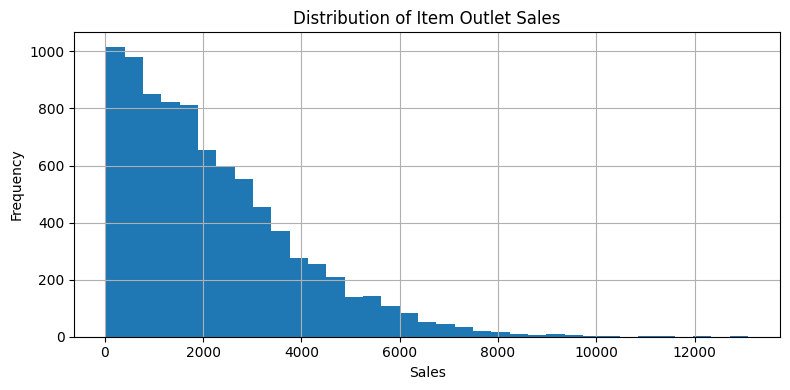

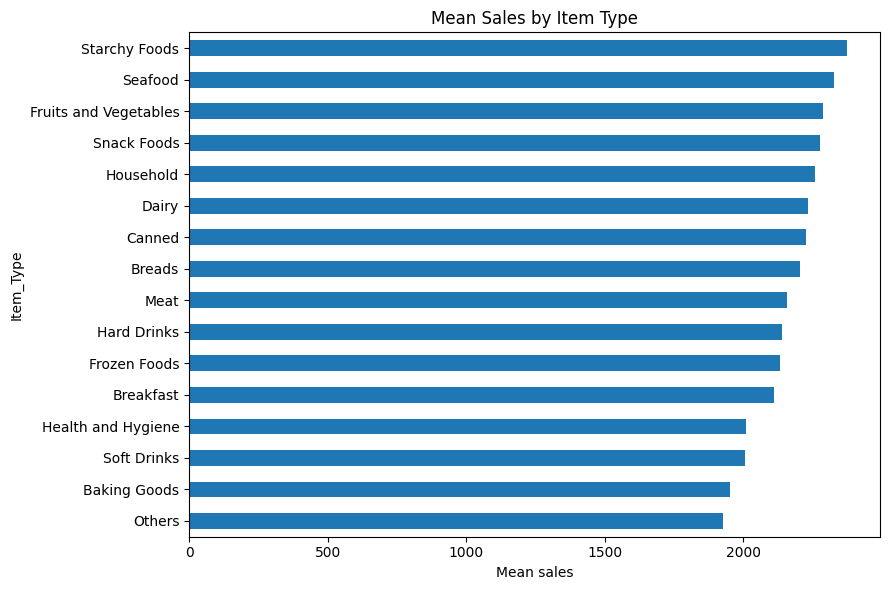

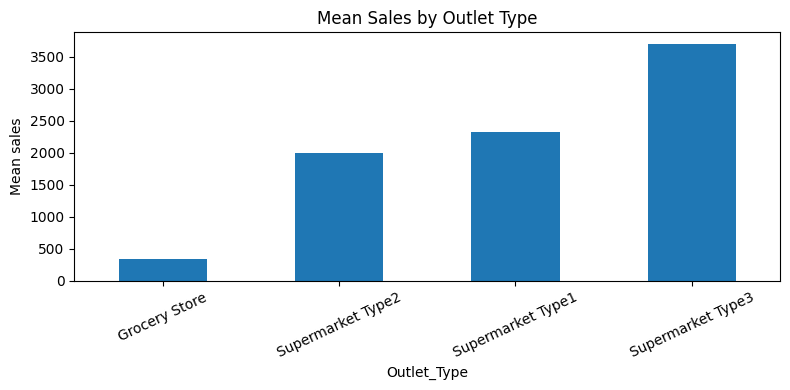

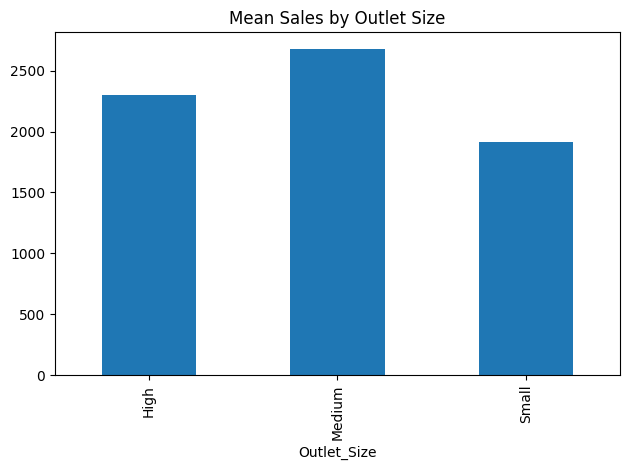

In [6]:
fig, ax = plt.subplots(figsize=(8,4)); train['Item_Outlet_Sales'].hist(bins=35, ax=ax); ax.set_title('Distribution of Item Outlet Sales'); ax.set_xlabel('Sales'); ax.set_ylabel('Frequency'); plt.tight_layout(); plt.show()
if 'Item_Type' in train.columns:
    train.groupby('Item_Type')['Item_Outlet_Sales'].mean().sort_values().plot(kind='barh',figsize=(9,6),title='Mean Sales by Item Type'); plt.xlabel('Mean sales'); plt.tight_layout(); plt.show()
if 'Outlet_Type' in train.columns:
    train.groupby('Outlet_Type')['Item_Outlet_Sales'].mean().sort_values().plot(kind='bar',figsize=(8,4),title='Mean Sales by Outlet Type'); plt.ylabel('Mean sales'); plt.xticks(rotation=25); plt.tight_layout(); plt.show()
if 'Outlet_Size' in train.columns:
    train.groupby('Outlet_Size')['Item_Outlet_Sales'].mean().plot(kind='bar',title='Mean Sales by Outlet Size'); plt.tight_layout(); plt.show()

## 4. Prepare features and validation split
Identifiers are kept available for the final output, but Item_Identifier is excluded from model predictors. Outlet identifier remains as a categorical predictor.

In [7]:
target='Item_Outlet_Sales'
ids = [c for c in ['Item_Identifier','Outlet_Identifier'] if c in train.columns and c in test.columns]
X = train.drop(columns=[target] + (['Item_Identifier'] if 'Item_Identifier' in train.columns else []))
y = train[target]
X_test = test.drop(columns=['Item_Identifier'] if 'Item_Identifier' in test.columns else [])
num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()
preprocessor = ColumnTransformer([
 ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), num_cols),
 ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])
X_train, X_val, y_train, y_val = train_test_split(X,y,test_size=0.2,random_state=42)
print('Numeric:', num_cols); print('Categorical:', cat_cols)

Numeric: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age']
Categorical: ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


## 5. Model comparison
Models are compared on a single validation split. RMSE is used as the selection criterion; MAE and R² are also reported.

In [8]:
models = {
 'Random Forest': RandomForestRegressor(n_estimators=300,min_samples_leaf=2,max_features=0.8,random_state=42,n_jobs=-1),
 'Extra Trees': ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,max_features=0.8,random_state=42,n_jobs=-1),
 'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=250,learning_rate=0.08,random_state=42)
}
results=[]; fitted_models={}; val_predictions={}
for name, model in models.items():
    pipe=Pipeline([('prep',preprocessor),('model',model)])
    pipe.fit(X_train,y_train)
    pred=pipe.predict(X_val)
    fitted_models[name]=pipe; val_predictions[name]=pred
    results.append({'Model':name,'MAE':mean_absolute_error(y_val,pred),'RMSE':mean_squared_error(y_val,pred)**0.5,'R2':r2_score(y_val,pred)})
results_df=pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(results_df)
best_name=results_df.loc[0,'Model']; best_model=models[best_name]
print('Selected model (lowest validation RMSE):',best_name)

,Model,MAE,RMSE,R2
0,Random Forest,741.590530,1063.162578,0.584133
1,Hist Gradient Boosting,738.656617,1066.562822,0.581468
2,Extra Trees,751.994635,1078.416980,0.572113


Selected model (lowest validation RMSE): Random Forest


## 6. Validation diagnostics

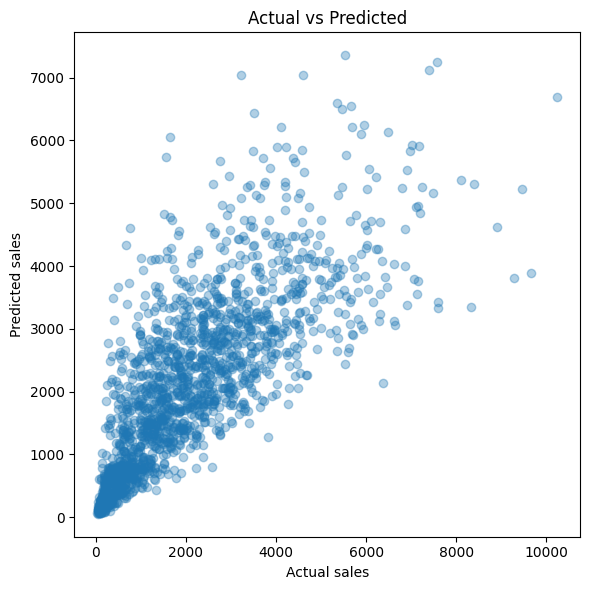

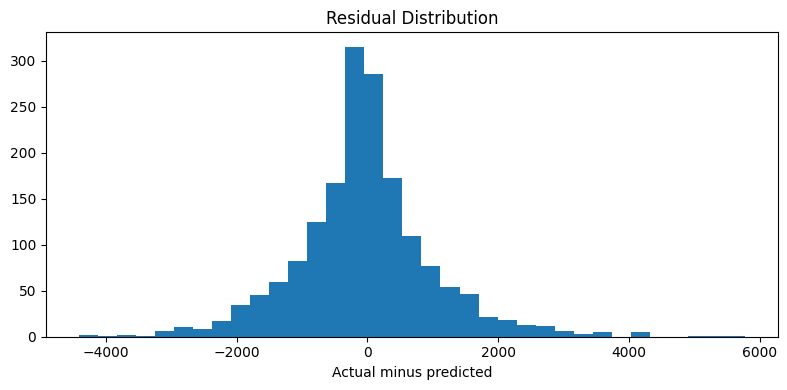

Validation MAE: 741.59
Validation RMSE: 1063.16
Validation R²: 0.5841


In [9]:
best_val_pred=val_predictions[best_name]
plt.figure(figsize=(6,6)); plt.scatter(y_val,best_val_pred,alpha=.35); plt.xlabel('Actual sales'); plt.ylabel('Predicted sales'); plt.title('Actual vs Predicted'); plt.tight_layout(); plt.show()
residuals=y_val-best_val_pred
plt.figure(figsize=(8,4)); plt.hist(residuals,bins=35); plt.title('Residual Distribution'); plt.xlabel('Actual minus predicted'); plt.tight_layout(); plt.show()
print('Validation MAE:', round(mean_absolute_error(y_val,best_val_pred),2))
print('Validation RMSE:', round(mean_squared_error(y_val,best_val_pred)**0.5,2))
print('Validation R²:', round(r2_score(y_val,best_val_pred),4))

## 7. Train selected model on full labelled data and generate predictions

In [10]:
final_pipeline=Pipeline([('prep',preprocessor),('model',best_model)])
final_pipeline.fit(X,y)
final_preds=final_pipeline.predict(X_test)
submission=pd.DataFrame()
for col in ['Item_Identifier','Outlet_Identifier']:
    if col in test.columns: submission[col]=test[col]
submission['Item_Outlet_Sales']=final_preds
display(submission.head(10))
submission.to_csv('BigMart_Sales_Predictions.csv',index=False)
print('Saved: BigMart_Sales_Predictions.csv')
files.download('BigMart_Sales_Predictions.csv')

,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1716.819904
1,FDW14,OUT017,1323.135008
2,NCN55,OUT010,617.810250
3,FDQ58,OUT017,2101.760913
4,FDY38,OUT027,6257.913888
5,FDH56,OUT046,1992.607013
6,FDL48,OUT018,658.654191
7,FDC48,OUT027,1669.903404
8,FDN33,OUT045,1204.800018
9,FDA36,OUT017,2756.718800


Saved: BigMart_Sales_Predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusion
The model comparison table identifies the model with the lowest validation RMSE. The final pipeline is refit on the full labelled dataset and generates sales estimates for the test rows. Use the measured validation metrics above when writing the final results. Sales estimates are model-based predictions and should not be interpreted as guaranteed sales.